# Лабораторна 2. Від сирих даних до нейромережі

У цій лабораторній роботі ви пройдете повний цикл роботи з табличним датасетом для задачі регресії — від завантаження до порівняння моделей:

- дослідницький аналіз даних (EDA): загальний огляд, гістограми, кореляції;
- обробка пропусків і викидів;
- інженерія ознак;
- baseline: множинна лінійна регресія;
- нейромережа — підбір архітектури, функцій активації, оптимізатора власними експериментами;
- чесне порівняння моделей на test за метриками регресії (MSE, RMSE, MAE, R²).

Демо-ноутбук з лекції 3-4 — основа, звертайтесь до нього як до довідника, коли щось незрозуміло.

## 0. Опрацюйте демо-ноутбук з лекції
Прогляньте пояснення ноутбуку і запустіть всі клітинки демо-ноутбуку (крім тих секцій, в яких вказано, що їх запускати не можна).
Після цього дайте тут відповідь на запитання:
1. Чому для заповнення пропусків було обрано метод kNN?
2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.
3. Які висновки після клітинки 2.6 в демо Ви можете зробити?
4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.
6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?
7. Чи оптимально вибрано кількість епох в 3.5?

### 0.1 Мої відповіді:
1. Метод kNN було обрано через те, що проста імпутація ігнорує зв'язки. Натомість kNN-імпутація тренує окрему модель для кожної колонки з пропусками, де рядки без пропусків стають навчальною множиною, а пропущене значення передбачається на основі інших ознак цього ж рядка.
2. Під час тренування модель використовує середньоквадратичну помилку, оскільки це диференційована функція, яка сильно штрафує за великі відхилення, що допомагає градієнтному спуску ефективно оновлювати ваги. Після тренування, на етапі оцінки, застосовують багато метрик, оскільки вони дають змогу людям краще інтерпретувати результати.
3. Оскільки всі ознаки перед навчанням пройшли стандартизацію, абсолютне значення ваги кожної ознаки прямо показує силу її впливу на прогнозовану ціну. Без стандартизації таке порівняння було б некоректним. Також після виконання коду ми можемо підтвердити ефективність інженерії ознак. Створені нові ознаки diag_coord та bedperroom, виявилися вагомими предикторами і не стали зайвими для лінійної моделі.
4. Baseline потрібен для того, щоб зрозуміти, чи має побудована модель сенс узагалі — якщо вона не може побити примітивний Baseline, вона безполєзна. Він вираховується шляхом передбачення завжди однієї й тієї ж середньої ціни, порахованої на тренувальній вибірці. Baseline для нейромережі виступає лінійна регресія. Вона слугує відправною точкою, щоб перевірити чи існують у даних нелінійні залежності, яких проста лінійна модель вловити не може.
5. Код написаний в окремій клітинці знизу
6. У клітинці 3.3 вказано архітектуру n_features → 64 → 32 → 1. Кількість вхідних ознак дорівнює 7 (було 8 ознак мінус 3 видалені плюс 2 нові).   Перший шар: 7 входів * 64 нейрони = 448. Плюс 64 зсуви. Разом = 512.Другий шар: 64 входи * 32 нейрони = 2048. Плюс 32 зсуви. Разом = 2080.Третій шар: 32 входи * 1 нейрон = 32 ваги. Плюс 1 зсув. Разом = 33.Загальна сума: 512 + 2080 + 33 = 2625 параметрів.
У лінійній регресії (Linear 7 → 1) їх лише 8 (7 ваг + 1 зсув), тому нейромережа має майже в 330 разів більше параметрів.
7. Ну судячи з висновків 3.9 обидві криві train та val на останніх епохах усе ще повільно спадають, при тому що жодних ознак overfitting немає моделі ще б не завадило декілька епох навчання.
 

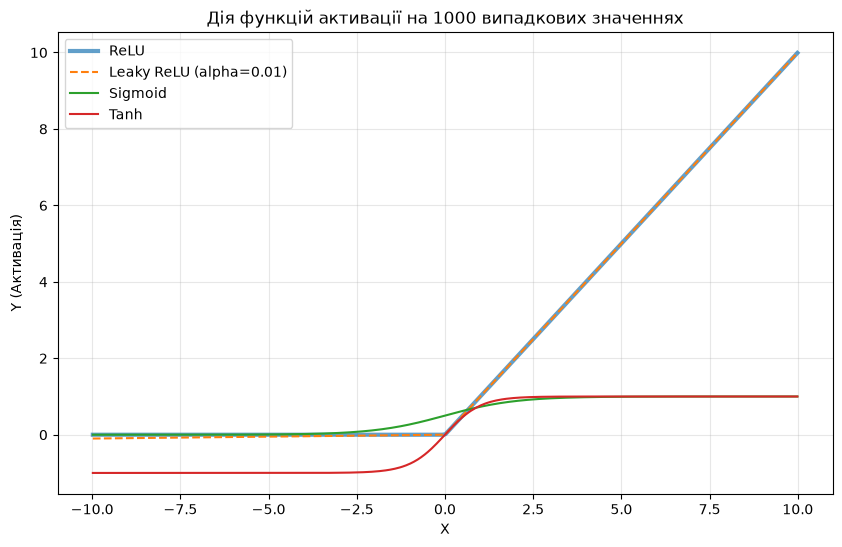

In [5]:
import numpy as np
import matplotlib.pyplot as plt

X = np.sort(np.random.uniform(-10, 10, 1000))

y_relu = np.maximum(0, X)
y_leaky_relu = np.where(X > 0, X, 0.01 * X)
y_sigmoid = 1 / (1 + np.exp(-X))
y_tanh = np.tanh(X)

# Будуємо графік
plt.figure(figsize=(10, 6))
plt.plot(X, y_relu, label="ReLU", linewidth=3, alpha=0.7)
plt.plot(X, y_leaky_relu, label="Leaky ReLU (alpha=0.01)", linestyle='--')
plt.plot(X, y_sigmoid, label="Sigmoid")
plt.plot(X, y_tanh, label="Tanh")

plt.title("Дія функцій активації на 1000 випадкових значеннях")
plt.xlabel("X")
plt.ylabel("Y (Активація)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

---
## 1. Датасети

Ви отримаєте один з 10 датасетів нижче. Усі — задачі регресії на Hugging Face: табличні дані, здебільшого числові ознаки, від кількасот до кількадесяти тисяч рядків.

1. **[King County House Sales](https://huggingface.co/datasets/kraina/house_sales_in_king_county)** — 21 613 продажів будинків (Вашингтон, 2014–2015). Таргет: `price`. ⚠️ `load_dataset("kraina/house_sales_in_king_county")` не працює (застарілий loading-скрипт) — вантажте напряму: `load_dataset("parquet", data_files="https://huggingface.co/datasets/kraina/house_sales_in_king_county/resolve/main/data/house_sales_king_county.parquet")`.
2. **[Diamonds](https://huggingface.co/datasets/jdxcosta/diamonds)** — 53 940 діамантів. Таргет: `price`. Ознаки: вага (`carat`), огранка, колір, чистота, розміри.
3. **[Concrete Compressive Strength](https://huggingface.co/datasets/foundry-ml/dataset_concrete_compressive_strength)** — 1 030 замісів бетону. Таргет: міцність на стиск. Усі ознаки числові (склад суміші + вік).
4. **[Auto MPG](https://huggingface.co/datasets/scikit-learn/auto-mpg)** — 398 автомобілів. Таргет: `mpg` (витрата пального). Найменший і найпростіший датасет зі списку.
5. **[Wine Quality](https://huggingface.co/datasets/codesignal/wine-quality)** — 1 599 (червоне) + 4 898 (біле) вин. Таргет: `quality` (оцінка 3–9). Усі ознаки — хімічний склад, числові.
6. **[Laptop Price](https://huggingface.co/datasets/Ammok/laptop_price_prediction)** — 977 + 325 ноутбуків. Таргет: `Price`. Частина ознак текстові (`RAM`, `Storage`, `CPU`) — доведеться парсити в числа.
7. **[Bike Sharing Demand](https://huggingface.co/datasets/t22000t/bike-sharing-tabular)** — 17 379 годинних записів прокату велосипедів. Таргет: `cnt`. Часові й погодні ознаки.
8. **[Ames House Prices](https://huggingface.co/datasets/t22000t/house-prices-tabular)** — 1 460 будинків, 79 ознак. Таргет: `SalePrice`. Найбільше категоріальних ознак зі списку — гарна практика на encoding.
9. **[Medical Insurance Cost](https://huggingface.co/datasets/harishsohani/medical-insurance-cost-prediction)** — 1 338 застрахованих. Таргет: `charges`. Компактний, мало ознак — хороший старт, якщо часу мало. ⚠️ У репозиторії кілька CSV одразу (`Xtrain`/`Xtest`/`insurance.csv`) — вкажіть файл явно: `load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")`.
10. **[Abalone](https://huggingface.co/datasets/mstz/abalone)** — 4 177 молюсків. Таргет: `number_of_rings` (вік). Усі ознаки — фізичні виміри, окрім `sex`.

Решта (2–5, 7–8, 10) вантажаться напряму — `load_dataset("<repo_id>")` без додаткових аргументів, HF-токен не потрібен.

### 1.1. Який датасет мій?

Визначте самі власний датасет: беремо Ваше ПІБ, рахуємо SHA-256 хеш, залишок від ділення на 10 — це індекс у списку датасетів вище (0 → перший, 9 → останній).

**Формат ПІБ:** точно як у списку групи — `Прізвище Ім'я По-батькові`, по одному пробілу між словами, без зайвих пробілів на початку/в кінці. Якщо використаєте інший формат - **не зарахую лабу**!!!

In [6]:
import hashlib

DATASETS = [
    "King County House Sales",
    "Diamonds",
    "Concrete Compressive Strength",
    "Auto MPG",
    "Wine Quality",
    "Laptop Price",
    "Bike Sharing Demand",
    "Ames House Prices",
    "Medical Insurance Cost",
    "Abalone",
]

FULL_NAME = "Кухар Артем Андрійович"  # TODO: впишіть своє ПІБ точно як у списку групи

dataset_index = int(hashlib.sha256(FULL_NAME.encode("utf-8")).hexdigest(), 16) % len(DATASETS)
print(f"Ваш датасет (#{dataset_index + 1}):", DATASETS[dataset_index])

Ваш датасет (#7): Bike Sharing Demand


---
## 2. Що потрібно зробити

Нижче — загальний план роботи, без коду: код і пояснення до кожного кроку дивіться в **демо-ноутбуці лекції 3-4**, номери розділів позначені в дужках. Ваша задача — повторити той самий підхід на своєму датасеті, а не скопіювати код один в один: у вашого датасету інші колонки, інші типи пропусків (чи їх взагалі нема), інші викиди (чи їх нема) — рішення на кожному кроці обґрунтовуйте під свої дані, а не тому, що "так було в демо".

### 2.1. Підготовка даних

1. Завантажте свій датасет (демо 1.1) і перетворіть на `pandas.DataFrame` (1.2).
2. Зробіть спліт **train / val / test** одразу, до будь-якого аналізу (1.3) — і поясніть своїми словами, чому саме в такому порядку (нагадування: data leakage).
3. Загальний огляд (`head`/`info`/`describe`, 1.4).
4. Обробка пропусків (1.5) — **якщо вони є**. Немає пропусків — так і напишіть, це теж валідний результат, не треба їх штучно вигадувати.
5. EDA (1.6): хоча б гістограми і кореляційна матриця. Що впадає в очі у ваших даних — capping, скошені розподіли, мультиколінеарність?
6. Обробка викидів (1.7) — **за потреби**, з обґрунтуванням: звідки взявся викид і чому саме таке рішення (видалити / трансформувати / залишити).
7. Інженерія ознак (1.8) — **за потреби**: чи є сенс комбінувати/прибирати ознаки з високою кореляцією між собою.

### 2.2. Baseline: множинна лінійна регресія

Стандартизація ознак (2.1), тензори (2.2), тренування `nn.Linear` (2.3), крива навчання (2.4), метрики на test — MSE/RMSE/MAE/R² (2.5), інтерпретація ваг (2.6).

Це ваш **варіант #1**, точка відліку для всього, що далі.

### 2.3. Нейромережа: щонайменше 2 різні архітектури

За зразком розділу 3 демо: `nn.Sequential` з прихованими шарами, ReLU, оптимізатор Adam.

Спробуйте **мінімум 2 архітектури**, які відрізняються не косметично — напр. різна кількість шарів, різна ширина шарів, чи інша функція активації (3.2). Кожна — окремий варіант.

### 2.4. Підбір гіперпараметрів: щонайменше 3 зміни

Візьміть архітектуру, яка показала себе краще, і поекспериментуйте з гіперпараметрами: learning rate, оптимізатор (SGD/Adam), кількість епох, розмір batch (якщо вирішите його ввести) тощо. Змінюйте **по одному параметру за раз** — інакше не зрозумієте, що саме вплинуло на результат.

**Разом (2.2 + 2.3 + 2.4):** щонайменше 5 варіантів моделі (1 лінійна + 2 архітектури + 2 гіперпараметри), до **10 варіантів** — якщо є час і бажання поекспериментувати більше, це тільки заохочується.

### 2.5. Логування і порівняння

Кожен варіант (2.2-2.4) логуйте в TensorBoard в окрему підпапку `RUNS_DIR` (як у 2.3/3.5 демо) — з осмисленою назвою (`linear`, `nn_v1_2layers`, `nn_v2_deeper`, `nn_v2_lr_0.001`, ...), щоб потім усі криві можна було накласти одна на одну (3.8 демо) і візуально порівняти.

Наприкінці зведіть усі варіанти в одну таблицю (модель → MSE/RMSE/MAE/R² на test) і дайте коротку письмову відповідь:
- Яка модель перемогла і наскільки суттєво?
- Чи виправдала себе нейромережа порівняно з лінійною регресією на вашому датасеті?
- Що з ваших змін (архітектура чи гіперпараметри) дало найбільший ефект?

In [ ]:
import torch
import torch.nn as nn
import pandas as pd
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from torch.utils.tensorboard import SummaryWriter
from sklearn.preprocessing import StandardScaler

---
### 2.1 Підготовка даних

Відділяємо цільову змінну та ознаки. Видаляємо 'casual' та 'registered', оскільки їх сума дорівнює 'cnt' (це цільовий витік) та 'instant' та 'dteday' не несуть числової цінності для моделі.

In [8]:
df = pd.read_csv("hour.csv")

X = df.drop(columns=['cnt', 'casual', 'registered', 'instant', 'dteday'])
y = df['cnt']


X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1765, random_state=42)

Розділення даних необхідно виконувати до етапу дослідження та стандартизації. Якщо стандартизувати весь датасет до спліту, статистична інформація про розподіл (середнє, стандартне відхилення) тестових даних "витече" в тренувальну вибірку (Data Leakage). Оцінка моделі на такому тестовому наборі буде нечесно оптимістичною.

In [9]:
print(X_train.info())
print(X_train.describe())
print("Пропуски в даних:\n", X_train.isnull().sum())

<class 'pandas.DataFrame'>
Index: 12164 entries, 6347 to 2135
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   season      12164 non-null  int64  
 1   yr          12164 non-null  int64  
 2   mnth        12164 non-null  int64  
 3   hr          12164 non-null  int64  
 4   holiday     12164 non-null  int64  
 5   weekday     12164 non-null  int64  
 6   workingday  12164 non-null  int64  
 7   weathersit  12164 non-null  int64  
 8   temp        12164 non-null  float64
 9   atemp       12164 non-null  float64
 10  hum         12164 non-null  float64
 11  windspeed   12164 non-null  float64
dtypes: float64(4), int64(8)
memory usage: 1.2 MB
None
             season            yr          mnth            hr       holiday  \
count  12164.000000  12164.000000  12164.000000  12164.000000  12164.000000   
mean       2.508468      0.504110      6.561164     11.563795      0.028773   
std        1.107185      0.500004      

Датасет hour.csv є повним та не містить жодного пропущеного значення. Додаткові методи імпутації не застосовуються.

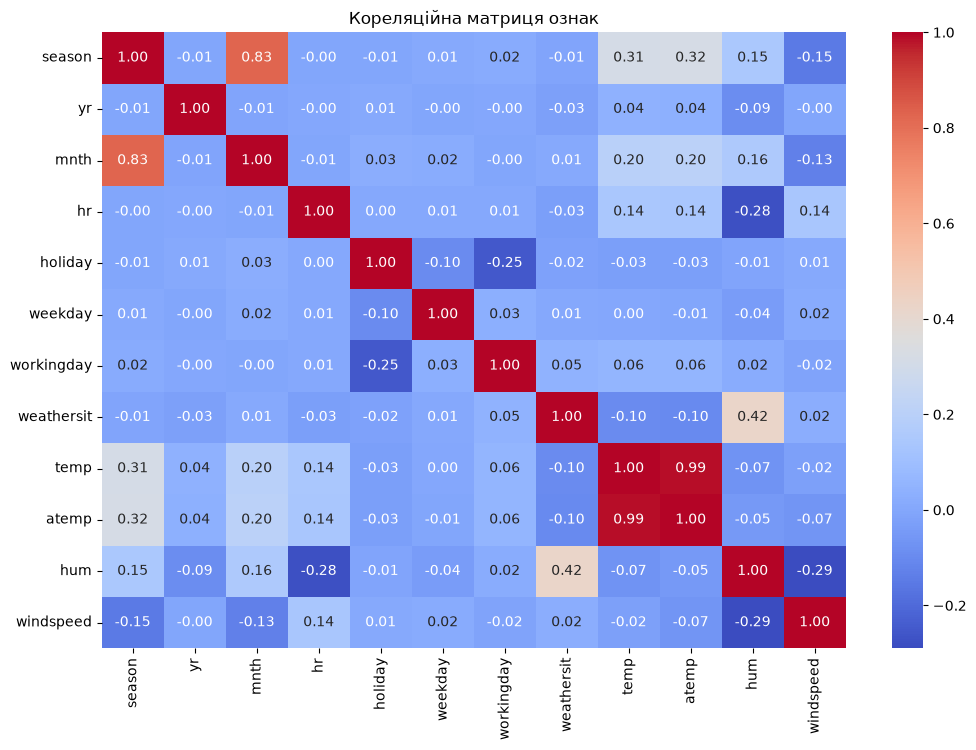

In [10]:
plt.figure(figsize=(12, 8))
sns.heatmap(X_train.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Кореляційна матриця ознак")
plt.show()

Матриця виявляє сувору мультиколінеарність. Фактична температура (temp) та відчуття температури (atemp) корелюють на 0.99. Це дублювання інформації, яке заважає лінійній моделі коректно розподілити ваги.

Цільова змінна cnt має сильний скіс вправо, а саме велика кількість годин з низьким попитом і різкі стрибки під час годин пік. Ці стрибки є даними, які відображають ключову поведінку користувачів, тому ми їх не видаляємо, щоб не порушити здатність моделі прогнозувати піковий попит. Натомість видаляємо 'atemp' для усунення мультиколінеарності.

In [11]:
X_train = X_train.drop(columns=['atemp'])
X_val = X_val.drop(columns=['atemp'])
X_test = X_test.drop(columns=['atemp'])

### 2.2 Baseline

Навчаємо скейлер тільки на train, а потім трансформуємо всі вибірки. Після чого конвертація в PyTorch тензори

In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)

X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1)

X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

Тренування лінійної моделі та логування

In [13]:
os.makedirs("models", exist_ok=True)

baseline_model = nn.Linear(X_train_t.shape[1], 1)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(baseline_model.parameters(), lr=0.01)

writer = SummaryWriter("runs/linear_baseline")
epochs = 500

for epoch in range(epochs):
    baseline_model.train()
    optimizer.zero_grad()
    predictions = baseline_model(X_train_t)
    loss = criterion(predictions, y_train_t)
    loss.backward()
    optimizer.step()
    
    baseline_model.eval()
    with torch.no_grad():
        val_preds = baseline_model(X_val_t)
        val_loss = criterion(val_preds, y_val_t)
    
    writer.add_scalars("Loss", {"train": loss.item(), "val": val_loss.item()}, epoch)

writer.close()
torch.save(baseline_model.state_dict(), "models/linear.pt")

Завдяки стандартизації всі ознаки приведені до одного масштабу. Абсолютне значення ваги вказує на силу впливу ознаки на фінальний прогноз ціни. Найвищі ваги в Bike Sharing Demand отримують температура та година доби.

In [14]:
weights = baseline_model.weight.detach().numpy()[0]
for feature, weight in zip(X_train.columns, weights):
    print(f"{feature}: {weight:.4f}")

season: 21.5880
yr: 42.1609
mnth: 1.6407
hr: 54.0897
holiday: -4.5422
weekday: 3.1079
workingday: 1.6144
weathersit: -2.1810
temp: 55.1106
hum: -37.2495
windspeed: 3.3234


### 2.3 Нейромережа: Архітектури

Проста нейромережа, має 2 приховані шари.

In [15]:
nn_v1 = nn.Sequential(
    nn.Linear(X_train_t.shape[1], 32),
    nn.ReLU(),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
)

optimizer_v1 = torch.optim.Adam(nn_v1.parameters(), lr=0.01)
writer_v1 = SummaryWriter("runs/nn_v1_2layers")

for epoch in range(epochs):
    nn_v1.train()
    optimizer_v1.zero_grad()
    loss = criterion(nn_v1(X_train_t), y_train_t)
    loss.backward()
    optimizer_v1.step()
    
    with torch.no_grad():
        val_loss = criterion(nn_v1(X_val_t), y_val_t)
    writer_v1.add_scalars("Loss", {"train": loss.item(), "val": val_loss.item()}, epoch)

writer_v1.close()
torch.save(nn_v1.state_dict(), "models/nn_v1.pt")

Просунута нейромережа, має 3 приховані шари і також Dropout

In [16]:
nn_v2 = nn.Sequential(
    nn.Linear(X_train_t.shape[1], 64),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
)

optimizer_v2 = torch.optim.Adam(nn_v2.parameters(), lr=0.01)
writer_v2 = SummaryWriter("runs/nn_v2_3layers_dropout")

for epoch in range(epochs):
    nn_v2.train()
    optimizer_v2.zero_grad()
    loss = criterion(nn_v2(X_train_t), y_train_t)
    loss.backward()
    optimizer_v2.step()
    
    with torch.no_grad():
        nn_v2.eval()
        val_loss = criterion(nn_v2(X_val_t), y_val_t)
    writer_v2.add_scalars("Loss", {"train": loss.item(), "val": val_loss.item()}, epoch)

writer_v2.close()
torch.save(nn_v2.state_dict(), "models/nn_v2.pt")

### 2.4 Підбір гіперпараметрів
На основі простої нейромережі застосуємо точкові зміни для аналізу впливу окремих параметрів. Всього буде три варіанти: Знижений Learning Rate, а саме 0.001 замість 0.01;
Заміна оптимізатора на RMSprop;
Заміна функції активації на LeakyReLU

#### Варіант 1:

In [21]:
nn_v3_lr = nn.Sequential(
    nn.Linear(X_train_t.shape[1], 32), 
    nn.ReLU(), 
    nn.Linear(32, 16), 
    nn.ReLU(), 
    nn.Linear(16, 1)
)
optimizer_lr = torch.optim.Adam(nn_v3_lr.parameters(), lr=0.001)
writer_lr = SummaryWriter("runs/nn_v3_lr0.001")
for epoch in range(epochs):
    nn_v3_lr.train()
    optimizer_lr.zero_grad()
    loss = criterion(nn_v3_lr(X_train_t), y_train_t)
    loss.backward()
    optimizer_lr.step()
    with torch.no_grad():
        nn_v3_lr.eval()
        val_loss = criterion(nn_v3_lr(X_val_t), y_val_t)
        
    writer_lr.add_scalars("Loss", {"train": loss.item(), "val": val_loss.item()}, epoch)
writer_lr.close()
torch.save(nn_v3_lr.state_dict(), "models/nn_v3.pt")

#### Варіант 2:

In [22]:
nn_v4_rms = nn.Sequential(
    nn.Linear(X_train_t.shape[1], 32), 
    nn.ReLU(), 
    nn.Linear(32, 16), 
    nn.ReLU(), 
    nn.Linear(16, 1)
)
optimizer_rms = torch.optim.RMSprop(nn_v4_rms.parameters(), lr=0.01)
writer_rms = SummaryWriter("runs/nn_v4_rmsprop")

for epoch in range(epochs):
    nn_v4_rms.train()
    optimizer_rms.zero_grad()
    loss = criterion(nn_v4_rms(X_train_t), y_train_t)
    loss.backward()
    optimizer_rms.step()
    
    # Валідація
    with torch.no_grad():
        nn_v4_rms.eval()
        val_loss = criterion(nn_v4_rms(X_val_t), y_val_t)
        
    writer_rms.add_scalars("Loss", {"train": loss.item(), "val": val_loss.item()}, epoch)

writer_rms.close()
torch.save(nn_v4_rms.state_dict(), "models/nn_v4.pt")

#### Варіант 3

In [23]:
nn_v5_leaky = nn.Sequential(
    nn.Linear(X_train_t.shape[1], 32),
    nn.LeakyReLU(0.01),
    nn.Linear(32, 16),
    nn.LeakyReLU(0.01),
    nn.Linear(16, 1)
)
optimizer_leaky = torch.optim.Adam(nn_v5_leaky.parameters(), lr=0.01)
writer_leaky = SummaryWriter("runs/nn_v5_leakyrelu")

for epoch in range(epochs):
    nn_v5_leaky.train()
    optimizer_leaky.zero_grad()
    loss = criterion(nn_v5_leaky(X_train_t), y_train_t)
    loss.backward()
    optimizer_leaky.step()
    
    # Валідація
    with torch.no_grad():
        nn_v5_leaky.eval()
        val_loss = criterion(nn_v5_leaky(X_val_t), y_val_t)
        
    writer_leaky.add_scalars("Loss", {"train": loss.item(), "val": val_loss.item()}, epoch)

writer_leaky.close()
torch.save(nn_v5_leaky.state_dict(), "models/nn_v5.pt")

### 2.5 Порівняння результатів та логування
Тепер проводимо оцінку моделей на вибірці Test

In [24]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

def evaluate_model(model, X_test, y_test, name):
    model.eval()
    with torch.no_grad():
        preds = model(X_test).numpy()
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    return {"Model": name, "MSE": mse, "RMSE": rmse, "MAE": mae, "R2": r2}

results = [
    evaluate_model(baseline_model, X_test_t, y_test_t, "Linear Baseline"),
    evaluate_model(nn_v1, X_test_t, y_test_t, "NN v1 (2 layers)"),
    evaluate_model(nn_v2, X_test_t, y_test_t, "NN v2 (3 layers + dropout)"),
    evaluate_model(nn_v3_lr, X_test_t, y_test_t, "NN v3 (LR=0.001)"),
    evaluate_model(nn_v4_rms, X_test_t, y_test_t, "NN v4 (RMSprop)"),
    evaluate_model(nn_v5_leaky, X_test_t, y_test_t, "NN v5 (LeakyReLU)")
]

results_df = pd.DataFrame(results)
results_df.to_csv("results.csv", index=False)
print(results_df)

                        Model           MSE        RMSE         MAE        R2
0             Linear Baseline  19355.380859  139.123617  104.846115  0.388845
1            NN v1 (2 layers)  18325.535156  135.371840   99.728111  0.421363
2  NN v2 (3 layers + dropout)  18091.246094  134.503703   98.211815  0.428761
3            NN v3 (LR=0.001)  19449.478516  139.461387  102.956223  0.385874
4             NN v4 (RMSprop)  10586.127930  102.888911   71.933678  0.665738
5           NN v5 (LeakyReLU)  18136.250000  134.670895   99.131737  0.427340


Майже всі моделі нейромережі обходить лінійну регресію для цього датасету, крім NN v3 вона майже на одному рівні.
Переможець - NN v4. Метрика $R^2$ підскочила до 0.665, а похибка MAE впала до 71 (у порівнянні зі 104 у лінійної моделі). Оптимізатор RMSprop чудово впорався зі специфікою даних. Він адаптує крок навчання окремо для кожного параметра. Це дозволило моделі знайти набагато кращий локальний мінімум за ті ж 500 епох, порівняно зі стандартним Adam. Тепер щодо NN v3. Її результат ($R^2 = 0.385$) виявився на рівні або навіть трохи гіршим за базову лінійну регресію. З матиматичної точки зору все правильно, через те що вдесятеро зменшився крок навчання (з 0.01 до 0.001), модель спускалася до мінімуму занадто повільно і просто не встигла "дійти" до найкращих показників за виділені 500 епох. В такому випадку було б доцільно збільшити кількість епох тоді б функція обійшла всі інші, але за 500 епох вона опинилася в стані недонавчання.

---
## 3. Gradio-застосунок: порівняння всіх варіантів наживо

Побудуйте аппку для своїх моделей

In [27]:
import gradio as gr
import numpy as np
import torch

best_model = nn_v4_rms
best_model.eval()

def predict_demand(yr, mnth, hr, holiday, weekday, workingday, weathersit, temp, hum, windspeed):
    if mnth in [3, 4, 5]:
        season = 1
    elif mnth in [6, 7, 8]:
        season = 2
    elif mnth in [9, 10, 11]:
        season = 3
    else: # 12, 1, 2
        season = 4
        
    input_features = np.array([[
        season, yr, mnth, hr, holiday, weekday, workingday, weathersit, temp, hum, windspeed
    ]])
    
    input_scaled = scaler.transform(input_features)
    input_t = torch.tensor(input_scaled, dtype=torch.float32)
    
    with torch.no_grad():
        prediction = best_model(input_t).item()
        
    return max(0, int(prediction))

inputs = [
    gr.Slider(0, 1, step=1, label="Year (0:2011, 1:2012)"),
    gr.Slider(1, 12, step=1, label="Month (1-12)"),
    gr.Slider(0, 23, step=1, label="Hour (0-23)"),
    gr.Radio([0, 1], label="Holiday?"),
    gr.Slider(0, 6, step=1, label="Weekday (0-6)"),
    gr.Radio([0, 1], label="Working Day?"),
    gr.Slider(1, 4, step=1, label="Weather (1:Clear - 4:Heavy Rain)"),
    gr.Slider(0.0, 1.0, label="Temperature (Normalized)"),
    gr.Slider(0.0, 1.0, label="Humidity (Normalized)"),
    gr.Slider(0.0, 1.0, label="Windspeed (Normalized)")
]

demo = gr.Interface(
    fn=predict_demand,
    inputs=inputs,
    outputs=gr.Textbox(label="Прогнозована кількість прокатів (cnt)"),
    title="Bike Sharing Demand Predictor",
    description="Інтерактивна панель прогнозування попиту на оренду велосипедів."
)

demo.launch()

* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


C:\Users\maliu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


---
### Як здавати лабу

У форму (https://forms.gle/8Dbc9zB8L5tsNuNEA) здати посилання на **публічний** репозиторій, який містить:

1. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Файли всіх натренованих варіантів моделі** (2.2-2.4) — лінійна регресія + всі варіанти нейромережі, кожен окремим `.pt` файлом.
3. **Логи TensorBoard** — папка `runs/` з усіма прогонами, щоб можна було відкрити криві навчання, не перезапускаючи ноутбук.
4. **Таблицю результатів** — `results.csv` з порівнянням усіх варіантів (модель, MSE, RMSE, MAE, R² на test).
5. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab2/nn_task.ipynb
/lab2/models/linear.pt
/lab2/models/nn_v1.pt
/lab2/models/nn_v2.pt
/lab2/models/...        (усі інші варіанти з 2.3-2.4)
/lab2/runs/*
/lab2/results.csv
```